# Lab 7
- **Student Name**: Daniel Alejandro Castillo Martin
- **Student ID**: N10019284
- **Course:** Advanced Deep Learning - AIGC-5500-0NA
- **Professor**: Hossein Pourmodheji
---

## Lab Overview

This lab implements and verifies a variational autoencoder (VAE) on 8 × 8 digit images. It compares the VAE with a plain autoencoder, measures how the KL weight affects reconstruction and prior sampling, and evaluates latent interpolation, class conditioning, and generated samples.

## 1. Imports and Setup

In [1]:
# Import required libraries
import torch
from torch import nn
from torch.nn import functional as F
from pathlib import Path
from IPython.display import Image, display

# Import the starter code
from scripts import lab07_starter as S

# Import custom modules
from src.vae import VAE, vae_loss, kl_to_standard_normal, reconstruction_nll
from src.experiments import train_matched_models
from src.evaluation import evaluate_matched_models

# Load the data
x_train, y_train, x_test, y_test = S.load_task(seed = 0)

In [2]:
# Define the dimensions of the model as constants
INPUT_DIM = 64
HIDDEN_DIM = 64
LATENT_DIM = 8

# Print the shapes of the training and test data
print(f'Training: {tuple(x_train.shape)} | Test: {tuple(x_test.shape)}')

Training: (1438, 64) | Test: (359, 64)


## 2. VAE Implementation and Verification

### 2.2 VAE Architecture

The encoder maps each 64-pixel image to the mean and log-variance of an 8-dimensional Gaussian. Reparameterization combines those values with standard normal noise so reconstruction gradients can reach the encoder. The decoder maps the sampled latent vector back to 64 pixel logits.

In [3]:
# Set the seed for reproducibility
torch.manual_seed(0)

# Initialize the VAE
vae = VAE(input_dim = INPUT_DIM, hidden_dim = HIDDEN_DIM, latent_dim = LATENT_DIM)

# Forward pass through the VAE
with torch.no_grad():
    logits, mu, logvar = vae(x_train[:4])

# Print the shapes of the decoder logits and the posterior mean and log-variance
print(f'Decoder logits: {tuple(logits.shape)}')
print(f'Posterior mean and log-variance: {tuple(mu.shape)}')

Decoder logits: (4, 64)
Posterior mean and log-variance: (4, 8)


### 2.3 VAE Loss

The VAE loss combines reconstruction error with a KL penalty. The reconstruction term sums binary cross-entropy over the 64 pixels. The KL term sums the divergence between the encoder’s Gaussian and the standard normal over the 8 latent dimensions. The weighted sum is averaged over the batch. The parameter $\beta$ controls the weight of the KL term.

In [4]:
# Calculate the initial VAE loss
with torch.no_grad():
    loss = vae_loss(vae, x_train[:4], beta = 1.0)

print(f'Initial VAE loss: {loss.item():.4f}')

Initial VAE loss: 44.3535


### 2.4 Closed-Form KL vs. Monte Carlo Estimate

For five randomly generated diagonal Gaussians, this check compares the closed-form KL divergence to a standard normal with a Monte Carlo estimate. The estimate averages $log q(z) - \log p(z)$ over samples drawn from $q$. Small differences are expected because the estimate uses a finite number of samples.

In [5]:
generator = torch.Generator().manual_seed(0)
n_gaussians = 5
n_samples = 100_000
shape = (n_gaussians, LATENT_DIM)

# Define five diagonal Gaussians and the standard normal prior
mu_check = torch.randn(shape, generator = generator)
logvar_check = 0.5 * torch.randn(shape, generator = generator)
posterior = torch.distributions.Normal(mu_check, torch.exp(0.5 * logvar_check))
prior = torch.distributions.Normal(torch.zeros_like(mu_check), torch.ones_like(mu_check))

# Draw samples from each posterior and sum log densities over latent dimensions
noise = torch.randn((n_samples, *shape), generator = generator)
z_samples = posterior.loc + posterior.scale * noise
log_ratios = (posterior.log_prob(z_samples) - prior.log_prob(z_samples)).sum(dim = -1)

# Compare the estimate with the closed form for each Gaussian
kl_mc = log_ratios.mean(dim = 0)
kl_closed = kl_to_standard_normal(mu_check, logvar_check)
absolute_error = (kl_closed - kl_mc).abs()
mc_standard_error = log_ratios.std(dim = 0) / n_samples**0.5

for i in range(n_gaussians):
    print(f'Gaussian {i + 1} | Closed form: {kl_closed[i]:.4f} | ' f'Monte Carlo: {kl_mc[i]:.4f} | Absolute error: {absolute_error[i]:.4f}')

agreement = (absolute_error <= 4 * mc_standard_error).all().item()
print(f'All estimates within four Monte Carlo standard errors: {agreement}')

Gaussian 1 | Closed form: 4.6179 | Monte Carlo: 4.6348 | Absolute error: 0.0169
Gaussian 2 | Closed form: 2.7566 | Monte Carlo: 2.7641 | Absolute error: 0.0075
Gaussian 3 | Closed form: 7.5045 | Monte Carlo: 7.4798 | Absolute error: 0.0247
Gaussian 4 | Closed form: 2.0781 | Monte Carlo: 2.0677 | Absolute error: 0.0104
Gaussian 5 | Closed form: 4.5055 | Monte Carlo: 4.4967 | Absolute error: 0.0088
All estimates within four Monte Carlo standard errors: True


### 2.5 Reconstruction Gradient Through the Latent Sample

This check measures the gradient of the reconstruction loss with respect to the weights of the encoder’s mean head. Both cases use the same batch and latent sample. Detaching the sample preserves its values while cutting the gradient path back to the encoder.

In [6]:
# Set the seed for reproducibility
torch.manual_seed(0)
# Select a batch of images
x_batch = x_train[:32]
# Encode the images
mu, logvar = vae.encode(x_batch)
z = vae.reparameterize(mu, logvar)
mean_weights = vae.mu_head.weight

# Measure the gradient through the reparameterized sample
reconstruction = reconstruction_nll(vae.decode(z), x_batch).mean()
connected_grad, = torch.autograd.grad(reconstruction, mean_weights)
connected_norm = connected_grad.norm().item()

# Repeat with the same latent values detached from the encoder
detached_reconstruction = reconstruction_nll(vae.decode(z.detach()), x_batch).mean()
detached_grad, = torch.autograd.grad(detached_reconstruction, mean_weights, allow_unused = True)
detached_norm = 0.0 if detached_grad is None else detached_grad.norm().item()

print(f'Gradient norm with reparameterization: {connected_norm:.6f}')
print(f'Gradient norm with detached sample: {detached_norm:.6f}')
print(f'Gradient check passed: {connected_norm > 0 and detached_norm == 0}')

Gradient norm with reparameterization: 0.689904
Gradient norm with detached sample: 0.000000
Gradient check passed: True


### 2.6 Negative ELBO at β = 1

With $\beta = 1$, the VAE loss should equal the negative ELBO estimated with one latent draw per image for the reconstruction term and an exact KL term. This check computes the ELBO separately and uses the same random seed for both calculations so they use the same latent draws.

In [7]:
# Select a batch of images
x_batch = x_train[:32]

# Calculate the VAE loss at beta = 1
with torch.no_grad():
    torch.manual_seed(0)
    loss_beta_1 = vae_loss(vae, x_batch, beta = 1.0)

    # Reset the seed so both forward passes use the same latent draws
    torch.manual_seed(0)
    logits, mu, logvar = vae(x_batch)

    # Compute the reconstruction log-likelihood and KL independently
    pixel_log_prob = x_batch * F.logsigmoid(logits)
    pixel_log_prob += (1 - x_batch) * F.logsigmoid(-logits)
    log_px_given_z = pixel_log_prob.sum(dim = 1)

    posterior = torch.distributions.Normal(mu, torch.exp(0.5 * logvar))
    prior = torch.distributions.Normal(torch.zeros_like(mu), torch.ones_like(mu))
    kl = torch.distributions.kl_divergence(posterior, prior).sum(dim = 1)
    negative_elbo = -(log_px_given_z - kl).mean()

# Calculate the absolute difference between the VAE loss and the negative ELBO
difference = (loss_beta_1 - negative_elbo).abs()
agreement = torch.isclose(loss_beta_1, negative_elbo, rtol = 0, atol = 1e-5)

# Print the results
print(f'VAE loss at beta = 1: {loss_beta_1.item():.6f}')
print(f'Negative ELBO: {negative_elbo.item():.6f}')
print(f'Absolute difference: {difference.item():.2e}')
print(f'ELBO check passed: {agreement.item()}')

VAE loss at beta = 1: 44.473660
Negative ELBO: 44.473656
Absolute difference: 3.81e-06
ELBO check passed: True


## 3. Autoencoder vs. VAE

### 3.1 Matched Training

The plain autoencoder and the VAE use the same data split, hidden width, latent size, and training budget. Each model is trained for 200 epochs with Adam, a learning rate of `2e-3`, and a batch size of 64. We run both models with seeds `0`, `1`, and `2`. The autoencoder trains with mean squared error, and the VAE trains with the negative ELBO at `beta = 1`.

In [8]:
# Define the training seeds
TRAINING_SEEDS = (0, 1, 2)
# Define the number of epochs
EPOCHS = 200
LEARNING_RATE = 2e-3
BATCH_SIZE = 64

# Train the matched models
matched_models = {}
# Train the matched models for each seed
for seed in TRAINING_SEEDS:
    # Train the matched models for the current seed
    matched_models[seed] = train_matched_models(
        x_train,
        input_dim = INPUT_DIM,
        hidden_dim = HIDDEN_DIM,
        latent_dim = LATENT_DIM,
        seed = seed,
        epochs = EPOCHS,
        lr = LEARNING_RATE,
        batch_size = BATCH_SIZE
        )
    print(f'Seed {seed}: finished training the AE and the VAE')

Seed 0: finished training the AE and the VAE
Seed 1: finished training the AE and the VAE
Seed 2: finished training the AE and the VAE


### 3.2 Evaluation and Results

Both models are evaluated on test reconstruction MSE and on 359 samples decoded from the standard normal prior. The VAE uses the posterior mean for deterministic reconstruction. For each seed, both decoders receive the same prior draws. All sample scores use the same feature network and held-out reference set. Latent spread is measured as the standard deviation of each code dimension across the training images.

In [9]:
# Train the feature network 
feature_net = S.train_feature_net(x_train, y_train, seed = 0)
feature_net.eval()
# Get the test features
test_features = S.get_features(feature_net, x_test)

matched_results = {}
print('Seed | Model | Test MSE | Frechet | Precision | Recall | Nearest train')

# Evaluate the matched models for each seed
for seed, (ae, vae) in matched_models.items():
    # Evaluate the matched models for the current seed
    matched_results[seed] = evaluate_matched_models(ae, vae, x_train, x_test, feature_net, test_features, seed = seed)
    # Print the results for the current seed
    for name, result in matched_results[seed].items():
        print(f'{seed} | {name} | {result["test_mse"]:.5f} | 'f'{result["frechet"]:.3f} | {result["precision"]:.3f} | ' f'{result["recall"]:.3f} | {result["nearest_train"]:.3f}')
# Print the results for the training code standard deviations by latent dimension
print('\nTraining code standard deviations by latent dimension')
for seed, results in matched_results.items():
    for name, result in results.items():
        spread = ', '.join(f'{value:.3f}' for value in result['code_std'])
        print(f'Seed {seed} | {name}: [{spread}]')

Seed | Model | Test MSE | Frechet | Precision | Recall | Nearest train
0 | AE | 0.01524 | 72.256 | 0.384 | 0.875 | 2.055
0 | VAE | 0.02592 | 14.331 | 0.922 | 0.448 | 1.141
1 | AE | 0.01508 | 88.199 | 0.382 | 0.772 | 2.149
1 | VAE | 0.02653 | 12.685 | 0.897 | 0.412 | 1.123
2 | AE | 0.01491 | 100.596 | 0.462 | 0.749 | 2.333
2 | VAE | 0.02626 | 15.171 | 0.908 | 0.432 | 1.125

Training code standard deviations by latent dimension
Seed 0 | AE: [0.684, 0.867, 0.565, 0.629, 0.689, 0.807, 0.531, 0.669]
Seed 0 | VAE: [0.944, 0.959, 0.936, 0.481, 0.022, 0.824, 0.020, 0.034]
Seed 1 | AE: [0.630, 0.573, 0.754, 0.645, 1.086, 0.659, 0.744, 0.647]
Seed 1 | VAE: [0.904, 0.445, 0.812, 0.912, 0.894, 0.021, 0.025, 0.038]
Seed 2 | AE: [0.719, 0.763, 0.753, 0.706, 0.610, 0.707, 0.767, 0.730]
Seed 2 | VAE: [0.892, 0.919, 0.906, 0.026, 0.536, 0.820, 0.032, 0.021]


### 3.3 Prior Sample Comparison

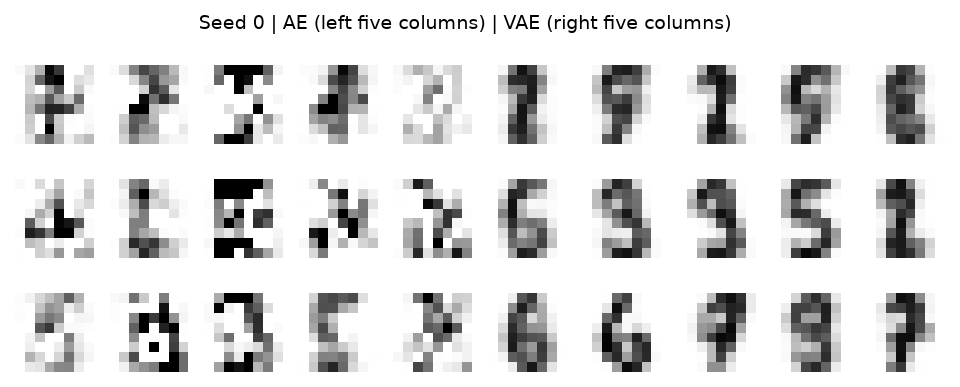

In [10]:
# Define the figure directory
figure_dir = Path('output/figures')
figure_dir.mkdir(parents = True, exist_ok = True)
figure_path = figure_dir / 'ae_vs_vae_prior_samples.png'

# Display five AE samples on the left and the corresponding VAE samples on the right
ae_samples = matched_results[0]['AE']['samples'][:15].reshape(3, 5, INPUT_DIM)
vae_samples = matched_results[0]['VAE']['samples'][:15].reshape(3, 5, INPUT_DIM)
sample_grid = torch.cat((ae_samples, vae_samples), dim = 1).reshape(-1, INPUT_DIM)

# Save the grid
S.save_grid(sample_grid, figure_path, ncols = 10, title = 'Seed 0 | AE (left five columns) | VAE (right five columns)')

# Display the image
Image(filename = str(figure_path))

The plain AE achieved lower test reconstruction MSE in all three seeds, averaging 0.01508 compared with 0.02624 for the VAE. For samples drawn from the standard normal prior, the VAE achieved a lower mean Fréchet distance (14.06 vs. 87.02) and higher mean precision (0.909 vs. 0.409). The VAE had lower mean recall (0.431 vs. 0.799), indicating that its samples covered less of the real data in feature space under this metric. In the seed 0 grid, the VAE produced more recognizable digit shapes, while several AE samples had fragmented strokes.

In each seed, three VAE posterior-mean dimensions had standard deviations below 0.04 across training images. The remaining five dimensions varied more across images. All eight AE code dimensions varied across training images. The AE's reconstruction objective placed no constraint on how its codes aligned with the standard normal prior. The VAE's KL term encouraged that alignment, consistent with its lower Fréchet distance and higher precision on prior samples.